# 03 – RFM, phân khúc khách hàng và độ ổn định theo quý

**Đầu vào:** bảng `fact_sales`, chỉ lấy khách đã định danh (`customer_key <> 0`).
**Đầu ra:** hai bảng `customer_segment` (phân khúc của từng khách) và `segment_transition` (khách chuyển giữa các phân khúc qua các quý) trong PostgreSQL để Power BI dùng.

**Các bước:**
1. Tính RFM (Recency – Frequency – Monetary) của từng khách trong 12 tháng gần nhất.
2. Log hóa và chuẩn hóa, chọn số cụm, phân cụm bằng K-Means.
3. Xem hồ sơ từng cụm, đặt tên phân khúc, tìm nhóm tạo doanh thu chính.
4. Với các mốc cuối quý, dùng **cùng bộ chuẩn hóa và cùng K-Means** để gán phân khúc, rồi so sánh giữa các quý.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from getpass import getpass
from pathlib import Path
from sqlalchemy import create_engine
from sqlalchemy.engine import URL
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

pd.options.display.float_format = "{:,.2f}".format
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
Path("figures").mkdir(exist_ok=True)           # nơi lưu biểu đồ

CUA_SO = 365          # RFM tính trên 365 ngày gần nhất tại mỗi ngày chụp
K = 4                 # số cụm 
SEED = 42
# Các mốc cuối quý có đủ 12 tháng lịch sử (dữ liệu bắt đầu 12/2009 nên các quý trước 12/2010 chưa đủ)
CUOI_QUY = ["2010-12-31", "2011-03-31", "2011-06-30", "2011-09-30"]

engine = create_engine(URL.create(
    "postgresql+psycopg2", username="postgres", password=getpass("Mật khẩu PostgreSQL: "),
    host="localhost", port=5432, database="Churn_Data"))

Mật khẩu PostgreSQL:  ········


## 1. Đọc giao dịch của khách đã định danh

In [2]:
tx = pd.read_sql("""
    SELECT customer_key, invoice_no, order_date, CAST(revenue AS DOUBLE PRECISION) AS revenue
    FROM fact_sales
    WHERE customer_key <> 0
""", engine)
tx["order_date"] = pd.to_datetime(tx["order_date"])
NGAY_CUOI = tx["order_date"].max()
print(f"{len(tx):,} dòng bán | {tx['customer_key'].nunique():,} khách | đến ngày {NGAY_CUOI.date()}")

775,246 dòng bán | 5,851 khách | đến ngày 2011-12-09


## 2. Tính RFM
- **Recency:** số ngày từ lần mua cuối đến ngày chụp (càng nhỏ càng tốt).
- **Frequency:** số hóa đơn trong 12 tháng gần nhất.
- **Monetary:** tổng doanh thu trong 12 tháng gần nhất.

In [3]:
def tinh_rfm(ngay_chup):
    """Trả về bảng RFM của từng khách trong 365 ngày tính đến ngay_chup."""
    ngay_chup = pd.Timestamp(ngay_chup)
    trong_cua_so = tx[(tx["order_date"] > ngay_chup - pd.Timedelta(days=CUA_SO)) & (tx["order_date"] <= ngay_chup)]
    nhom = trong_cua_so.groupby("customer_key")
    return pd.DataFrame({
        "recency": (ngay_chup - nhom["order_date"].max()).dt.days,
        "frequency": nhom["invoice_no"].nunique(),
        "monetary": nhom["revenue"].sum(),
    })

rfm_cuoi = tinh_rfm(NGAY_CUOI)       # snapshot cuối = ngày cuối của dữ liệu
print(f"Snapshot {NGAY_CUOI.date()}: {len(rfm_cuoi):,} khách có mua trong {CUA_SO} ngày gần nhất")
rfm_cuoi.describe(percentiles=[.5, .9, .99])

Snapshot 2011-12-09: 4,260 khách có mua trong 365 ngày gần nhất


,recency,frequency,monetary
count,"4,260.00","4,260.00","4,260.00"
mean,87.54,4.12,"1,901.21"
std,94.11,7.28,"8,154.32"
min,0.00,1.00,2.90
50%,50.00,2.00,653.57
90%,249.10,9.00,"3,447.70"
99%,352.41,28.00,"17,008.67"
max,364.00,188.00,"279,138.02"


In [4]:
# Dữ liệu lệch phải rất mạnh (một số ít khách mua rất nhiều) nên cần log1p trước khi chạy K-Means
cot = ["recency", "frequency", "monetary"]
pd.DataFrame({"do_lech_truoc_log": rfm_cuoi[cot].skew(), "do_lech_sau_log1p": np.log1p(rfm_cuoi[cot]).skew()})

,do_lech_truoc_log,do_lech_sau_log1p
recency,1.23,-0.48
frequency,11.51,1.22
monetary,20.93,0.35


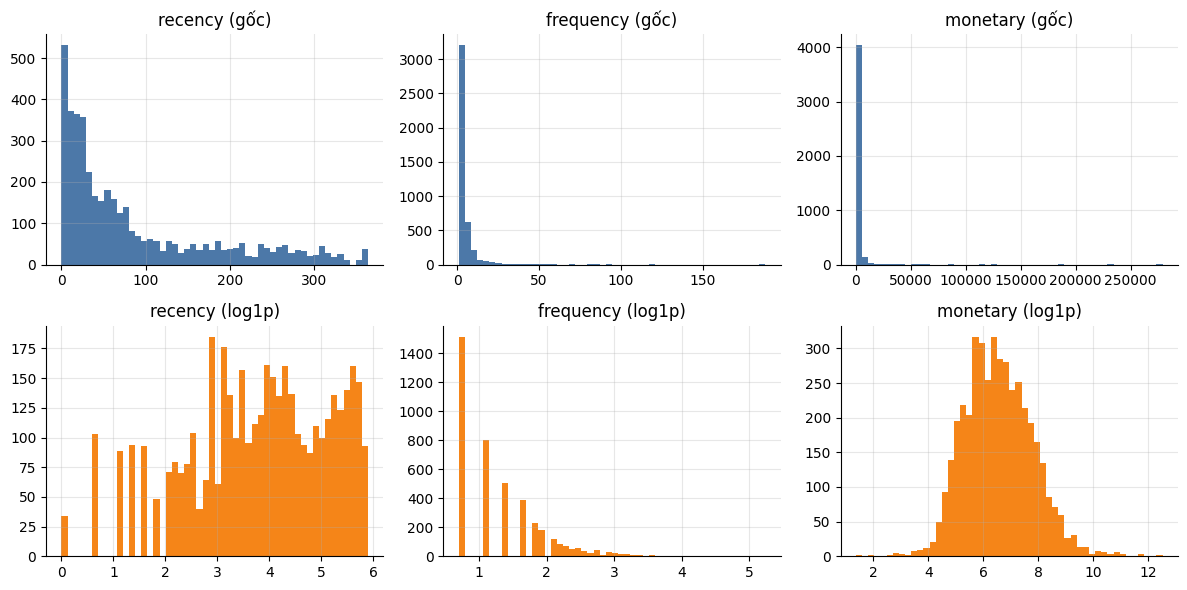

In [5]:
fig, ax = plt.subplots(2, 3, figsize=(12, 6))
for j, c in enumerate(cot):
    ax[0, j].hist(rfm_cuoi[c], bins=50, color="#4C78A8"); ax[0, j].set_title(c + " (gốc)")
    ax[1, j].hist(np.log1p(rfm_cuoi[c]), bins=50, color="#F58518"); ax[1, j].set_title(c + " (log1p)")
plt.tight_layout(); plt.savefig("figures/03_rfm_phan_phoi.png", dpi=150); plt.show()

## 3. Chọn số cụm
Log hóa rồi chuẩn hóa (z-score), thử k từ 2 đến 8. Elbow (inertia) và silhouette chỉ để tham khảo; số cụm cuối cùng còn phải có ý nghĩa nghiệp vụ.

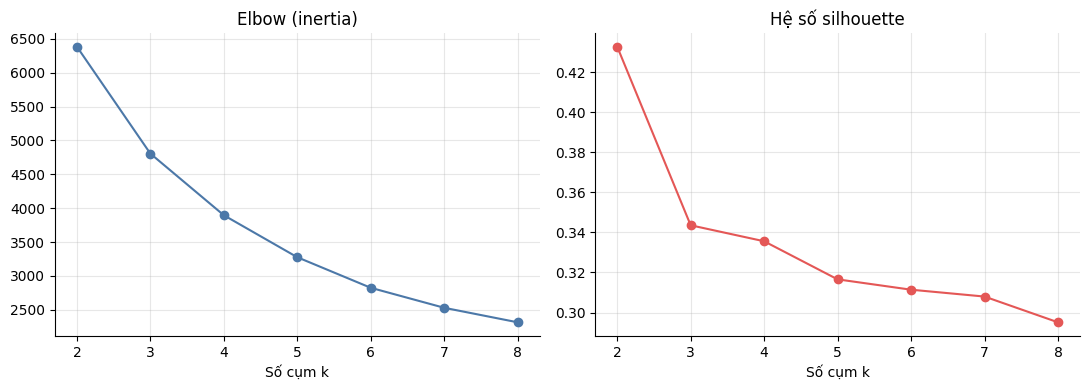

,k,inertia,silhouette
0,2,"6,384.32",0.43
1,3,"4,806.59",0.34
2,4,"3,896.79",0.34
3,5,"3,277.10",0.32
4,6,"2,826.11",0.31
5,7,"2,530.84",0.31
6,8,"2,316.79",0.30


In [6]:
scaler = StandardScaler().fit(np.log1p(rfm_cuoi[cot]))          # bộ chuẩn hóa này sẽ dùng lại cho các quý
X = scaler.transform(np.log1p(rfm_cuoi[cot]))

ket_qua_k = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X)
    ket_qua_k.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette_score(X, km.labels_)})
ket_qua_k = pd.DataFrame(ket_qua_k)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ket_qua_k["k"], ket_qua_k["inertia"], marker="o", color="#4C78A8"); ax[0].set_title("Elbow (inertia)")
ax[1].plot(ket_qua_k["k"], ket_qua_k["silhouette"], marker="o", color="#E45756"); ax[1].set_title("Hệ số silhouette")
for a in ax: a.set_xlabel("Số cụm k")
plt.tight_layout(); plt.savefig("figures/03_chon_k.png", dpi=150); plt.show()
ket_qua_k

## 4. Phân cụm K-Means và đặt tên phân khúc
Mỗi cụm được **xếp hạng** theo tâm cụm (Frequency và Monetary càng cao, Recency càng thấp thì càng tốt), rồi đặt tên theo thứ hạng.
**Sau khi chạy, hãy đọc bảng hồ sơ bên dưới và kiểm tra tên có hợp lý không**.
Lưu ý: phân khúc RFM chỉ mô tả hành vi, chưa phải nhãn rời bỏ (churn).

In [7]:
model = KMeans(n_clusters=K, n_init=20, random_state=SEED).fit(X)

# Điểm của mỗi cụm trên tâm cụm đã chuẩn hóa (cột: recency, frequency, monetary)
tam = model.cluster_centers_
diem = -tam[:, 0] + tam[:, 1] + tam[:, 2]
thu_hang = diem.argsort()[::-1]                       # cụm tốt nhất đứng đầu
ten = ["VIP", "Trung thành", "Tiềm năng", "Ngủ đông (nguy cơ)"]      # từ tốt nhất đến kém nhất (cần đúng K tên)
ten_cum = {int(cum): ten[i] for i, cum in enumerate(thu_hang)}      # số cụm -> tên phân khúc
thu_tu = [ten_cum[int(c)] for c in thu_hang]
print(ten_cum)

{1: 'VIP', 3: 'Trung thành', 2: 'Tiềm năng', 0: 'Ngủ đông (nguy cơ)'}


In [8]:
def gan_phan_khuc(rfm):
    """Thêm điểm R/F/M (1–5), số cụm và tên phân khúc vào bảng RFM, bằng bộ chuẩn hóa và K-Means đã huấn luyện."""
    rfm = rfm.copy()
    # Điểm 1–5 theo phân vị (5 = tốt nhất); rank() để xử lý các giá trị trùng nhau
    rfm["r_score"] = pd.qcut(rfm["recency"].rank(method="first", ascending=False), 5, labels=False) + 1
    rfm["f_score"] = pd.qcut(rfm["frequency"].rank(method="first"), 5, labels=False) + 1
    rfm["m_score"] = pd.qcut(rfm["monetary"].rank(method="first"), 5, labels=False) + 1
    rfm["rfm_score"] = rfm["r_score"].astype(str) + rfm["f_score"].astype(str) + rfm["m_score"].astype(str)
    rfm["cluster"] = model.predict(scaler.transform(np.log1p(rfm[cot])))
    rfm["segment"] = rfm["cluster"].map(ten_cum)
    return rfm

seg_cuoi = gan_phan_khuc(rfm_cuoi)

ho_so = seg_cuoi.groupby("segment").agg(
    so_khach=("recency", "size"), recency_tb=("recency", "mean"), recency_trung_vi=("recency", "median"),
    frequency_tb=("frequency", "mean"), monetary_tb=("monetary", "mean"), doanh_thu=("monetary", "sum")).reindex(thu_tu)
ho_so["ti_le_khach_pct"] = ho_so["so_khach"] / ho_so["so_khach"].sum() * 100
ho_so["ti_trong_doanh_thu_pct"] = ho_so["doanh_thu"] / ho_so["doanh_thu"].sum() * 100
ho_so

,so_khach,recency_tb,recency_trung_vi,frequency_tb,monetary_tb,doanh_thu,ti_le_khach_pct,ti_trong_doanh_thu_pct
segment,,,,,,,,
VIP,687,10.48,7.00,13.27,"7,533.02","5,175,183.95",16.13,63.90
Trung thành,1190,63.90,50.00,4.03,"1,667.34","1,984,135.26",27.93,24.50
Tiềm năng,795,17.73,17.00,1.98,491.56,"390,793.76",18.66,4.83
Ngủ đông (nguy cơ),1588,173.53,169.00,1.31,345.75,"549,053.07",37.28,6.78


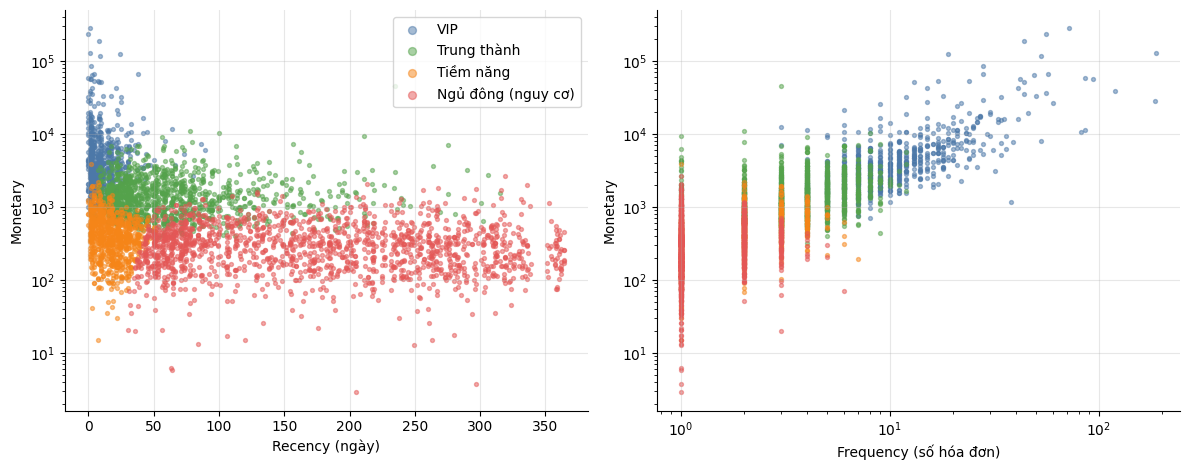

In [9]:
mau = dict(zip(thu_tu, ["#4C78A8", "#54A24B", "#F58518", "#E45756"]))
fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
for ten_pk in thu_tu:
    d = seg_cuoi[seg_cuoi["segment"] == ten_pk]
    ax[0].scatter(d["recency"], d["monetary"], s=8, alpha=0.5, color=mau[ten_pk], label=ten_pk)
    ax[1].scatter(d["frequency"], d["monetary"], s=8, alpha=0.5, color=mau[ten_pk], label=ten_pk)
ax[0].set_xlabel("Recency (ngày)"); ax[1].set_xlabel("Frequency (số hóa đơn)")
for a in ax: a.set_ylabel("Monetary"); a.set_yscale("log")
ax[1].set_xscale("log"); ax[0].legend(markerscale=2)
plt.tight_layout(); plt.savefig("figures/04_phan_khuc_scatter.png", dpi=150); plt.show()

### 4.1. Nhóm tạo doanh thu chính
So sánh tỷ trọng số khách với tỷ trọng doanh thu của từng phân khúc. Phân khúc có tỷ trọng doanh thu lớn hơn nhiều so với tỷ trọng khách là nhóm tạo doanh thu chính.

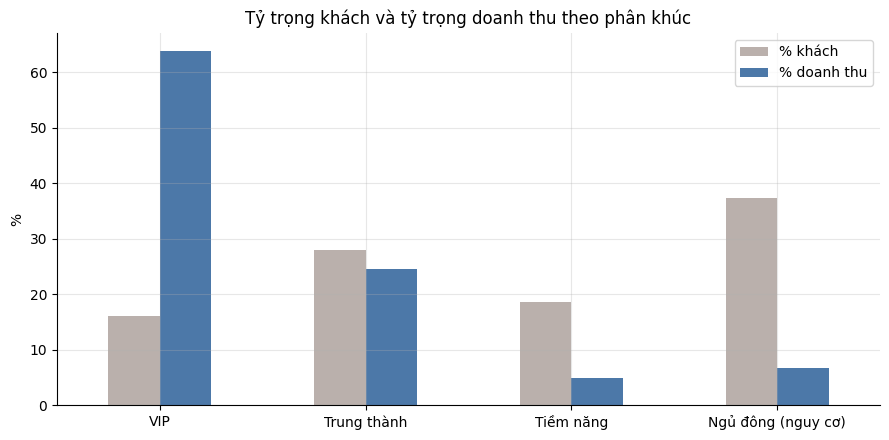

In [10]:
ax = ho_so[["ti_le_khach_pct", "ti_trong_doanh_thu_pct"]].plot.bar(figsize=(9, 4.5), color=["#BAB0AC", "#4C78A8"])
ax.set_xlabel(""); ax.set_ylabel("%"); ax.set_title("Tỷ trọng khách và tỷ trọng doanh thu theo phân khúc")
ax.legend(["% khách", "% doanh thu"]); plt.xticks(rotation=0)
plt.tight_layout(); plt.savefig("figures/04_ti_trong_doanh_thu.png", dpi=150); plt.show()

## 5. Độ ổn định của phân khúc giữa các quý
Tại mỗi cuối quý: tính RFM 12 tháng gần nhất rồi gán phân khúc bằng **cùng** `scaler` và `model` ở phần 4 (nhờ vậy tên phân khúc giữa các quý so sánh được với nhau).
Khách có ở quý trước nhưng không mua lần nào trong 12 tháng tính đến quý sau được xếp vào trạng thái `Không hoạt động`.

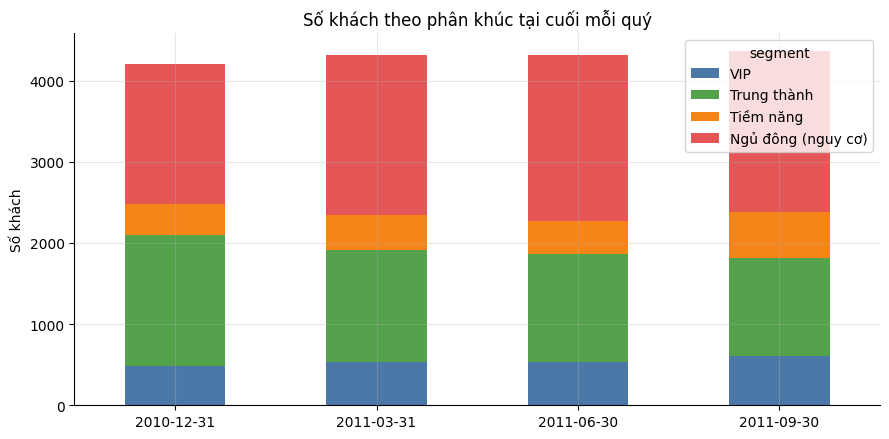

segment,VIP,Trung thành,Tiềm năng,Ngủ đông (nguy cơ)
2010-12-31,488,1606,391,1717
2011-03-31,528,1388,424,1976
2011-06-30,537,1332,401,2043
2011-09-30,608,1204,568,1983


In [11]:
snaps = {}                                   # ngày chụp -> bảng RFM + phân khúc
for ngay in CUOI_QUY:
    snaps[pd.Timestamp(ngay)] = gan_phan_khuc(tinh_rfm(ngay))

quy_mo = pd.DataFrame({d.date(): s["segment"].value_counts() for d, s in snaps.items()}).reindex(thu_tu).T
quy_mo.plot.bar(stacked=True, figsize=(9, 4.5), color=[mau[t] for t in thu_tu])
plt.title("Số khách theo phân khúc tại cuối mỗi quý"); plt.xticks(rotation=0); plt.ylabel("Số khách")
plt.tight_layout(); plt.savefig("figures/05_quy_mo_phan_khuc.png", dpi=150); plt.show()
quy_mo

In [12]:
# So sánh từng cặp quý liên tiếp
cac_ngay = list(snaps)
chuyen_dich = {}        # (quý trước, quý sau) -> bảng chuyển dịch
ket_qua_ari = []

for a, b in zip(cac_ngay[:-1], cac_ngay[1:]):
    cu, moi = snaps[a], snaps[b]

    # Phân khúc quý sau của từng khách quý trước (không còn mặt ở quý sau => "Không hoạt động")
    sau = moi["segment"].reindex(cu.index).fillna("Không hoạt động")
    bang = pd.crosstab(cu["segment"], sau).reindex(index=thu_tu, columns=thu_tu + ["Không hoạt động"], fill_value=0)
    chuyen_dich[(a, b)] = bang

    # ARI: mức giống nhau của hai cách phân cụm trên các khách có mặt ở cả hai quý (1 = giống hệt, 0 = ngẫu nhiên)
    chung = cu.index.intersection(moi.index)
    ari = adjusted_rand_score(cu.loc[chung, "cluster"], moi.loc[chung, "cluster"])
    ket_qua_ari.append({"tu_quy": a.date(), "den_quy": b.date(), "khach_chung": len(chung), "ARI": ari})

ket_qua_ari = pd.DataFrame(ket_qua_ari)
ket_qua_ari

,tu_quy,den_quy,khach_chung,ARI
0,2010-12-31,2011-03-31,3931,0.39
1,2011-03-31,2011-06-30,3966,0.36
2,2011-06-30,2011-09-30,3921,0.36


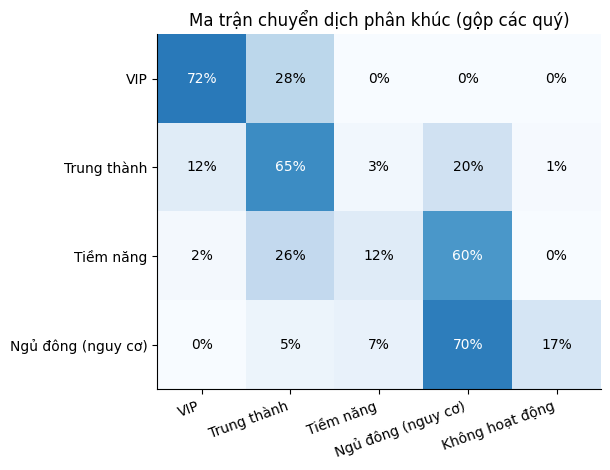

In [13]:
# Ma trận chuyển dịch gộp tất cả các quý (hàng: quý trước, cột: quý sau)
gop = sum(chuyen_dich.values())
gop_pct = gop.div(gop.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.imshow(gop_pct.values, cmap="Blues", vmin=0, vmax=100)
ax.set_xticks(range(gop_pct.shape[1])); ax.set_xticklabels(gop_pct.columns, rotation=20, ha="right")
ax.set_yticks(range(gop_pct.shape[0])); ax.set_yticklabels(gop_pct.index)
for i in range(gop_pct.shape[0]):
    for j in range(gop_pct.shape[1]):
        v = gop_pct.values[i, j]
        ax.text(j, i, f"{v:.0f}%", ha="center", va="center", color="white" if v > 55 else "black")
ax.set_title("Ma trận chuyển dịch phân khúc (gộp các quý)"); ax.grid(False)
plt.tight_layout(); plt.savefig("figures/05_ma_tran_chuyen_dich.png", dpi=150); plt.show()

## 6. Ghi kết quả vào PostgreSQL cho Power BI

In [14]:
# Bảng phân khúc của từng khách tại mọi ngày chụp (các mốc cuối quý + snapshot cuối)
khung = []
for ngay, bang in list(snaps.items()) + [(NGAY_CUOI, seg_cuoi)]:
    t = bang.reset_index()
    t["snapshot_date"] = ngay.date()
    t["is_latest"] = (ngay == NGAY_CUOI)
    khung.append(t)
customer_segment = pd.concat(khung, ignore_index=True)[
    ["customer_key", "snapshot_date", "is_latest", "recency", "frequency", "monetary",
     "r_score", "f_score", "m_score", "rfm_score", "cluster", "segment"]]

# Bảng chuyển dịch dạng dài (mỗi dòng: từ phân khúc nào, sang phân khúc nào, bao nhiêu khách)
dai = []
for (a, b), bang in chuyen_dich.items():
    bang = bang.copy(); bang.index.name = "tu_phan_khuc"; bang.columns.name = "den_phan_khuc"
    d = bang.reset_index().melt(id_vars="tu_phan_khuc", value_name="so_khach")
    d["tu_ngay"], d["den_ngay"] = a.date(), b.date()
    dai.append(d)
segment_transition = pd.concat(dai, ignore_index=True)

for ten_bang, bang in [("customer_segment", customer_segment), ("segment_transition", segment_transition)]:
    bang.to_sql(ten_bang, engine, if_exists="replace", index=False)
    print(f"Đã ghi {ten_bang}: {len(bang):,} dòng")

Đã ghi customer_segment: 21,454 dòng
Đã ghi segment_transition: 60 dòng


In [18]:
customer_segment.head(3)

,customer_key,snapshot_date,is_latest,recency,frequency,monetary,r_score,f_score,m_score,rfm_score,cluster,segment
0,12346,2010-12-31,False,186,2,169.36,1,2,1,121,0,Ngủ đông (nguy cơ)
1,12347,2010-12-31,False,24,2,"1,323.32",5,2,4,524,3,Trung thành
2,12348,2010-12-31,False,15,2,873.96,5,2,3,523,2,Tiềm năng


In [19]:
segment_transition.head(3)

,tu_phan_khuc,den_phan_khuc,so_khach,tu_ngay,den_ngay
0,VIP,VIP,353,2010-12-31,2011-03-31
1,Trung thành,VIP,167,2010-12-31,2011-03-31
2,Tiềm năng,VIP,2,2010-12-31,2011-03-31


In [20]:
# Kiểm tra: số khách ở snapshot cuối trong PostgreSQL phải bằng trong notebook
n_db = int(pd.read_sql("SELECT COUNT(*) AS n FROM customer_segment WHERE is_latest", engine)["n"][0])
print("Snapshot cuối trong PostgreSQL:", n_db, "| trong notebook:", len(seg_cuoi), "| khớp:", n_db == len(seg_cuoi))

Snapshot cuối trong PostgreSQL: 4260 | trong notebook: 4260 | khớp: True


## 7. Tổng kết 
- Phân khúc chỉ xây trên khách đã định danh; khách `Unknown` không có trong kết quả.
- Số cụm `K` chọn dựa trên elbow, silhouette và ý nghĩa nghiệp vụ. Nếu đổi `K`, phải đổi danh sách `ten` cho đủ K tên.
- Phân khúc RFM **chưa phải** nhãn churn; mối liên hệ giữa phân khúc và rủi ro rời bỏ sẽ kiểm tra ở bước sau.
- ARI giữa các quý (bảng `ket_qua_ari`) và hồ sơ phân khúc (bảng `ho_so`) được ghi trực tiếp vào báo cáo; không cần lưu vào PostgreSQL.
- Hạn chế: chỉ có 4 mốc cuối quý đủ 12 tháng lịch sử; quý 4/2011 chưa đủ dữ liệu nên không đưa vào phân tích ổn định.